# Стохастическое моделирование: Языковые марковские модели и непрерывные случайные процессы

## Задание №1

**Датасет:** 5 книг "Песнь льда и огня" на английском языке

Шаги выполнения:
1. Загрузка текстовых файлов
2. Предобработка: очистка от спецсимволов, приведение к нижнему регистру, токенизация
3. Построение матрицы переходов $P$ (в виде словаря частот для экономии памяти, так как матрица для текста сильно разрежена)
4. Оценка адекватности (генерация)
5. Бонус: сравнение цепи 1-го порядка с цепью 2-го порядка

### 1. Загрузка и подготовка датасета

#### Дискретная цепь Маркова и пространство состояний
**Определение:** Случайный процесс $(X_k)_{k=1}^n$, где $X_k$ принимают значения из множества $E$ (не умоляя общности, $E = \{1, 2, 3...\}$ — это множество состояний).

Цепь называется Марковской, если выполняется условие: $\forall n \ge 2, \forall x_1...x_n \in E$
$$P(X_n = x_n \mid X_{n-1} = x_{n-1}, X_{n-2} = x_{n-2}, \dots, X_1 = x_1) = P(X_n = x_n \mid X_{n-1} = x_{n-1})$$
*(«Будущее зависит только от настоящего»)*

На этапе загрузки и предобработки датасета мы формируем наше пространство состояний $E$. В нашем случае множеством $E$ будет являться словарь всех уникальных токенов (слов и знаков препинания), встречающихся в тексте

In [ ]:
import re
import random
import os
import glob
from collections import defaultdict, Counter

### 2. Предобработка датасета

In [ ]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"n't", " n't", text)
    text = re.sub(r"'s", " 's", text)
    text = re.sub(r"'ve", " 've", text)
    text = re.sub(r'([.?!,;:"\(\)\[\]])', r' \1 ', text)
    text = re.sub(r'[^a-z \.\?\!\,\;\"\']', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.split()

def load_all_books(path):
    all_tokens = []
    files = sorted(glob.glob(path))

    if not files:
        print("Файлы не найдены! Проверьте путь к папке.")
        return []

    print(f"Найдено файлов для загрузки: {len(files)}")

    for file_path in files:
        with open(file_path, 'r') as file:
            text = file.read()
            all_tokens.extend(preprocess_text(text))
            all_tokens.append('###')
            print(f"Загружена книга: {os.path.basename(file_path)}")

    return all_tokens

tokens = load_all_books(path_to_books)

print(f"\nВсего токенов по всем книгам: {len(tokens)}")
print(f"Пример токенов: {tokens[:20]}")

Найдено файлов для загрузки: 5
Загружена книга: 1-A_Game_of_Thrones.txt
Загружена книга: 2-A_Clash_of_Kings.txt
Загружена книга: 3-A_Storm_of_Swords.txt
Загружена книга: 4-A_Feast_for_Crows.txt
Загружена книга: 5-A_Dance_with_Dragons.txt

Всего токенов по всем книгам: 2143795
Пример токенов: ['a', 'game', 'of', 'thrones', 'book', 'one', 'of', 'a', 'song', 'of', 'ice', 'and', 'fire', 'by', 'george', 'r', '.', 'r', '.', 'martin']


### 3. Построение переходной матрицы (Цепь Маркова 1-го порядка)

#### Переходная матрица и однородные цепи
**Переходная матрица $P_{ij}$:** Матрица, элементы которой задают вероятность перехода за один шаг: $p_{ij}(n) = P(X_n = j \mid X_{n-1} = i)$.
Важное свойство матрицы: сумма вероятностей по каждой строке равна 1: $\sum_j p_{ij}(n) = 1$.

Если $P_{ij}$ не зависят от $n$ (времени/шага), то цепь называется однородной.

Для генерации текста мы предполагаем, что вероятность появления слова зависит только от предыдущего слова и не меняется от того, в начале или в конце книги мы находимся (однородная цепь).
Так как словарь слов (размер $E$) огромный, классическая двумерная матрица не поместится в память (и будет почти полностью состоять из нулей). Мы реализуем переходную матрицу $P$ как словарь словарей.

In [ ]:
def build_markov_model_1st_order(tokens):
    transition_counts = defaultdict(Counter)

    for i in range(len(tokens) - 1):
        current_state = tokens[i]
        next_state = tokens[i + 1]
        transition_counts[current_state][next_state] += 1

    transition_matrix = defaultdict(dict)
    for current_state, counts in transition_counts.items():
        total_transitions = sum(counts.values())
        for next_state, count in counts.items():
            transition_matrix[current_state][next_state] = count / total_transitions

    return transition_matrix

markov_matrix_1 = build_markov_model_1st_order(tokens)
print(f"Количество уникальных состояний (слов): {len(markov_matrix_1)}")

Количество уникальных состояний (слов): 26004


### 4. Генерация фраз и проверка адекватности
#### Распределение вероятностей и уравнение Колмогорова-Чепмена
Связь между состояниями выражается через **уравнение Колмогорова-Чепмена**:
$$p_{ij}(n+m) = \sum_k p_{ik}(n) \cdot p_{kj}(m)$$
В матричном виде: $(P^{n+m})_{ij} = (P^n)_{i,*} \cdot (P^m)_{*,j}$.

**Распределение вероятностей в момент времени $n$:** $p(n) = (P^T)^n \cdot p(0)$.
Вероятность того, что мы за $n$ шагов перейдем из $k$ в $j$: $p_{kj}(n) = P(X_n = j \mid X_1 = k)$.

Генерация текста — это симуляция случайного блуждания по графу Марковской цепи. Мы задаем начальное состояние $p(0)$ и рекурсивно совершаем $n$ шагов, выбирая следующее состояние пропорционально вероятностям $p_{ij}$.

In [ ]:
def generate_sentence_1st_order(model, start_word=None, max_length=20):
    if start_word is None or start_word not in model:
        states = [s for s in model.keys() if s not in ['.', '!', '?', ',']]
        if not states:
            return ""
        current_word = random.choice(states)
    else:
        current_word = start_word

    sentence = [current_word]

    for _ in range(max_length - 1):
        if current_word not in model or len(model[current_word]) == 0:
            break

        next_words = list(model[current_word].keys())
        probabilities = list(model[current_word].values())

        current_word = random.choices(next_words, weights=probabilities, k=1)[0]
        sentence.append(current_word)

        if current_word in ['.', '!', '?']:
            break

    result = " ".join(sentence)
    result = re.sub(r' ([.?!])', r'\1', result)
    return result.capitalize()

print("--- Генерация наивным способом (Цепь 1-го порядка) ---")
for i in range(5):
    print(f"{i+1}: {generate_sentence_1st_order(markov_matrix_1)}")

--- Генерация наивным способом (Цепь 1-го порядка) ---
1: Myself.
2: Wagering on watch with him , called , " you'll give him , but not feel the gusts that?
3: Arraying them from blount.
4: Condolence as grey to hear their elder bolton might make that?
5: Cusp of tears of the yard with the butt of these creatures.


### 5. Дополнительно: Сравнение с другим NLP-подходом (Цепи Маркова 2-го порядка)

#### Эргодичность и классификация состояний
Классификация состояний дискретной цепи:
* **Вероятность в первый раз вернуться в $k$:** $f_k(n) = P(X_n=k, X_{n-1} \neq k, \dots, X_2 \neq k \mid X_1=k)$.
* **Вероятность вернуться (когда-либо):** $F_k = \sum_{n=1}^\infty f_k(n)$. Состояние возвратное, если $F_k = 1$, и невозвратное, если $F_k \neq 1$.
* Состояние $i$ — **существенное** $\iff \forall j \in E: i \to j \implies j \to i$.

**Стационарное распределение и эргодичность:**
* Стационарное распределение $\Pi$: $P^T \Pi = \Pi$. Среднее время первого возврата: $\mu_{jj} = \frac{1}{\Pi_j}$.
* **Эргодичная цепь**: $\exists ! \text{ стац. распр. } \Pi$ (стационарное распределение единственно).
* **Сильно эргодичная цепь**: $\lim_{n \to \infty} p_{ij}(n) = p_j^* > 0 \quad (p^* = \Pi)$.
* **Критерий сильной эргодичности:** Конечная цепь сильно эргодична $\iff$ она неразложима и апериодическая.
* **Теорема эргодичности:** Пусть $V_i(n) = \sum_{k=1}^n \mathbb{I}(X_k = i)$. Цепь эрг. $\implies \frac{V_i(n)}{n} \xrightarrow{a.s.} \Pi_i$ и $\frac{E V_i(n)}{n} \to \Pi_i$.

Наивная дискретная цепь Маркова 1-го порядка часто генерирует бессмыслицу. Текстовая цепь **не является сильно эргодичной**, так как содержит невозвратные состояния (слова, встречающиеся 1 раз) и не является неразложимой (из точки мы искусственно прерываем цепь).

Чтобы повысить адекватность, мы усложняем пространство $E$, делая состоянием пару слов.

In [ ]:
def build_markov_model_2nd_order(tokens):
    transition_counts = defaultdict(Counter)

    for i in range(len(tokens) - 2):
        current_state = (tokens[i], tokens[i+1])
        next_state = tokens[i+2]
        transition_counts[current_state][next_state] += 1

    transition_matrix = defaultdict(dict)
    for current_state, counts in transition_counts.items():
        total_transitions = sum(counts.values())
        for next_state, count in counts.items():
            transition_matrix[current_state][next_state] = count / total_transitions

    return transition_matrix

markov_matrix_2 = build_markov_model_2nd_order(tokens)

def generate_sentence_2nd_order(model, max_length=20):
    valid_starts = [state for state in model.keys() if state[0] not in ['.', '?', '!',  ',']]
    if not valid_starts: return ""

    current_state = random.choice(valid_starts)
    sentence = list(current_state)

    for _ in range(max_length - 2):
        if current_state not in model or len(model[current_state]) == 0:
            break

        next_words = list(model[current_state].keys())
        probabilities = list(model[current_state].values())

        next_word = random.choices(next_words, weights=probabilities, k=1)[0]
        sentence.append(next_word)

        if next_word in ['.', '!', '?']:
            break

        current_state = (current_state[1], next_word)

    result = " ".join(sentence)
    result = re.sub(r' ([.?!])', r'\1', result)
    return result.capitalize()

print("--- Генерация с использованием цепи 2-го порядка ---")
for i in range(5):
    print(f"{i+1}: {generate_sentence_2nd_order(markov_matrix_2)}")

--- Генерация с использованием цепи 2-го порядка ---
1: Weese frowned at her , no , she commanded.
2: Robert commands it , where ser cortnay answered , from orkwood , called the lightning flashed , and delay all
3: Shed appeared.
4: Devoured summerhall on the longsword , but othell yarwyck and marsh will sway him.
5: Lion helmet had been raw from shouting that he could see was the thing that was not a sight as


### Оценка адекватности (Вывод)

Обучение на полном корпусе (2.14 млн токенов, 26 тыс. состояний) позволило получить максимально точные статистические оценки матрицы переходов $P$

1. **Цепь 1-го порядка:** Большой объем данных не решает проблему бессмысленности текста. Из-за «короткой памяти» ($P(X_n \mid X_{n-1})$) дисперсия переходов слишком велика. Модель использует правильную лексику, но полностью теряет грамматический контекст

2. **Цепь 2-го порядка:** Учет двух предыдущих состояний радикально снижает энтропию выбора. Матрица переходов становится сильно разреженной, и случайное блуждание удерживается в рамках правильного английского синтаксиса. Фразы получаются осмысленными и стилистически точными

**Итог:** Для адекватного стохастического моделирования языка порядок цепи важнее объема выборки. Цепь 2-го порядка в сочетании с большим датасетом успешно имитирует реальный текст

---

## Задание №2

## Моделирование динамики велосипеда в системе Divvy Bikeshare (Чикаго)

**Датасет:** Divvy Bicycle Sharing — поездки за Q1 2019  
**Источник:** https://divvy-tripdata.s3.amazonaws.com/Divvy_Trips_2019_Q1.zip  
**Период:** январь 2019 года, велосипед №3457 (100 поездок)  

**Объект моделирования:** один физический велосипед.  
В каждый момент времени он находится ровно в одном из двух состояний:

- **Состояние 0** — велосипед стоит на стоянке (доступен)  
- **Состояние 1** — велосипед в поездке (занят)  

Переходы между состояниями происходят в случайные моменты времени —  
это классическая **непрерывная цепь Маркова** с двумя состояниями.

Ключевое преимущество датасета: известны и время начала (`start_time`),  
и время конца (`end_time`) каждой поездки — оба параметра модели  
$\lambda$ и $\mu$ оцениваются непосредственно из данных.


## 1. Непрерывная цепь Маркова

Случайный процесс $\{X(t),\, t \ge 0\}$ со счётным пространством состояний $S$
называется **непрерывной цепью Маркова**, если выполняется свойство Маркова:

$$P\bigl(X(t)=j \mid X(s),\, u < s\bigr) = P\bigl(X(t)=j \mid X(s)\bigr), \quad s < t$$

В нашей задаче $S = \{0, 1\}$, где $0$ — велосипед на стоянке, $1$ — в поездке.

## 2. Инфинитезимальная матрица $Q$

| Переход | Событие | Интенсивность |
|---------|---------|---------------|
| $0 \to 1$ | пользователь берёт велосипед | $\lambda$ |
| $1 \to 0$ | пользователь заканчивает поездку | $\mu$ |

$$Q = \begin{pmatrix} -\lambda & \lambda \\ \mu & -\mu \end{pmatrix}$$

λ — интенсивность (частота) перехода из состояния 0 в состояние 1 (начало поездки)

μ — интенсивность перехода из состояния 1 в состояние 0 (конец поездки)

Свойства $Q$: внедиагональные элементы $\ge 0$, каждая строка суммируется в $0$.


## 3. Уравнения Колмогорова-Феллера

Матрица переходных вероятностей $P(t) = e^{Qt}$ удовлетворяет:

$$\frac{d}{dt}P(t) = P(t)\,Q, \qquad P(0) = I$$

Для двухсостояниевой цепи — аналитическое решение:

$$P(t) = \frac{1}{\lambda+\mu}\begin{pmatrix}
\mu + \lambda e^{-(\lambda+\mu)t} & \lambda\bigl(1 - e^{-(\lambda+\mu)t}\bigr) \\
\mu\bigl(1 - e^{-(\lambda+\mu)t}\bigr) & \lambda + \mu e^{-(\lambda+\mu)t}
\end{pmatrix}$$

## 4. Стационарное распределение

Вектор $\pi = (\pi_0, \pi_1)$ из условий $\pi Q = 0$, $\pi_0 + \pi_1 = 1$:

$$\boxed{\pi_0 = \frac{\mu}{\lambda + \mu}, \qquad \pi_1 = \frac{\lambda}{\lambda + \mu}}$$

$\pi_1$ — доля времени, которую велосипед проводит в поездке.

## 5. Эргодичность

При $\lambda, \mu > 0$ цепь **всегда эргодична**: она неразложима и возвратна.  
По эргодической теореме:

$$\lim_{t \to \infty} p_{ij}(t) = \pi_j, \qquad
\frac{1}{T}\int_0^T \mathbf{1}[X(t)=j]\,dt \;\xrightarrow{T\to\infty}\; \pi_j \quad\text{п.н.}$$


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import zipfile, io, requests

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

In [ ]:
URL = "https://divvy-tripdata.s3.amazonaws.com/Divvy_Trips_2019_Q1.zip"

print("Скачиваем Divvy Q1 2019...")
r = requests.get(URL, timeout=60)
with zipfile.ZipFile(io.BytesIO(r.content)) as z:
    fname = [f for f in z.namelist() if f.endswith('.csv')][0]
    df = pd.read_csv(z.open(fname))

df['start_time'] = pd.to_datetime(df['start_time'])
df['end_time']   = pd.to_datetime(df['end_time'])

df = df[(df['start_time'] >= '2019-01-01') &
        (df['start_time'] <  '2019-02-01')].copy()

best_bike = df.groupby('bikeid').size().idxmax()
bike_df = (df[df['bikeid'] == best_bike][['start_time','end_time']]
             .sort_values('start_time')
             .reset_index(drop=True))

print(f" Велосипед №{best_bike}: {len(bike_df)} поездок в январе 2019")
print(f" Период: {bike_df['start_time'].min().date()} — {bike_df['end_time'].max().date()}")
bike_df.head()


Скачиваем Divvy Q1 2019...
✓ Велосипед №3457: 100 поездок в январе 2019
  Период: 2019-01-01 — 2019-01-31


,start_time,end_time
0,2019-01-01 16:39:10,2019-01-01 16:42:25
1,2019-01-01 17:51:02,2019-01-01 17:59:02
2,2019-01-02 22:03:25,2019-01-02 22:12:51
3,2019-01-03 07:42:03,2019-01-03 07:45:57
4,2019-01-03 08:24:09,2019-01-03 08:42:19


In [ ]:
# длительности поездок и стоянок в днях
bike_df['ride_days'] = (bike_df['end_time'] -
                        bike_df['start_time']).dt.total_seconds() / 86400
bike_df['gap_days']  = (bike_df['start_time'] -
                        bike_df['end_time'].shift(1)).dt.total_seconds() / 86400

n = len(bike_df)                        # число поездок
time_in_1 = bike_df['ride_days'].sum()          # суммарное время в поездке
time_in_0 = bike_df['gap_days'].dropna().sum()  # суммарное время на стоянке

# MLE: λ = n / T₀,  μ = n / T₁
lam = n / time_in_0
mu  = n / time_in_1

# стационарное распределение
pi_0 = mu  / (lam + mu)
pi_1 = lam / (lam + mu)

# Реальная доля из данных
real_pi_1 = time_in_1 / (time_in_0 + time_in_1)
real_pi_0 = 1 - real_pi_1

print(f"Число поездок:                  {n}")
print(f"Суммарное время в поездке:  {time_in_1:.2f}  ({time_in_1*24*60/n:.1f} мин/поездка)")
print(f"Суммарное время на стоянке: {time_in_0:.2f}  ({time_in_0*24*60/n:.1f} мин/стоянка)")
print(f"")
print(f"λ (интенс. начала поездки):     {lam:.4f} / день")
print(f"μ (интенс. конца поездки):      {mu:.4f} / день")
print(f"")
print(f"π₀ = P(на стоянке):  {pi_0:.4f}  ({pi_0*100:.1f}%)")
print(f"π₁ = P(в поездке):   {pi_1:.4f}  ({pi_1*100:.1f}%)")
print(f"")
print(f"Из данных напрямую:")
print(f"π₀ (реальное):       {real_pi_0:.4f}  ({real_pi_0*100:.1f}%)")
print(f"π₁ (реальное):       {real_pi_1:.4f}  ({real_pi_1*100:.1f}%)")

Число поездок:                  100
Суммарное время в поездке:  0.84  (12.1 мин/поездка)
Суммарное время на стоянке: 29.17  (420.0 мин/стоянка)

λ (интенс. начала поездки):     3.4285 / день
μ (интенс. конца поездки):      118.6993 / день

π₀ = P(на стоянке):  0.9719  (97.2%)
π₁ = P(в поездке):   0.0281  (2.8%)

Из данных напрямую:
π₀ (реальное):       0.9719  (97.2%)
π₁ (реальное):       0.0281  (2.8%)


Инфинитезимальная матрица Q:
[[  -3.4285    3.4285]
 [ 118.6993 -118.6993]]
сумма строк: [0. 0.]


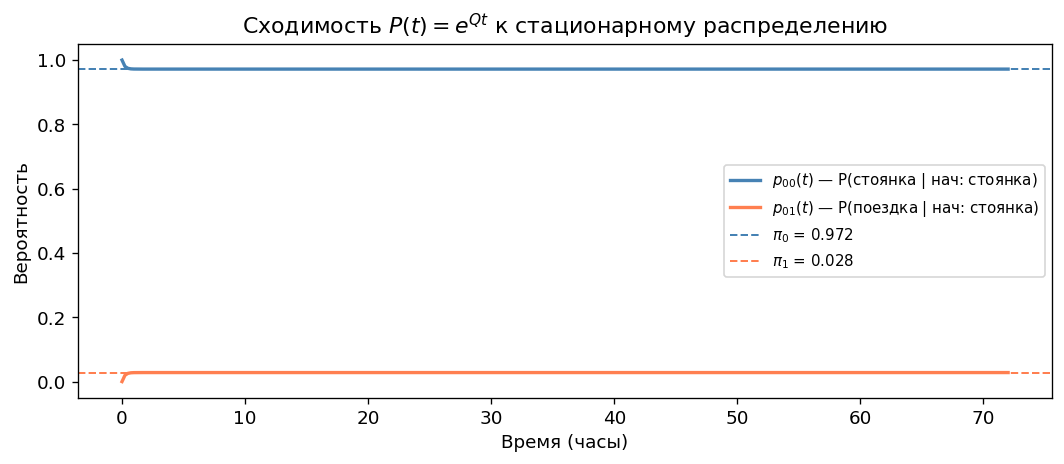

In [ ]:
Q = np.array([[-lam,  lam],
              [ mu,  -mu]])

print("Инфинитезимальная матрица Q:")
print(np.round(Q, 4))
print(f"сумма строк: {Q.sum(axis=1).round(10)}")

# аналитическая P(t)
def P_t(t):
    s = lam + mu
    e = np.exp(-s * t)
    return (1/s) * np.array([
        [mu + lam*e,   lam*(1-e)],
        [mu*(1-e),     lam + mu*e]
    ])

ts = np.linspace(0, 3, 300)  # дни
p00 = [P_t(t)[0,0] for t in ts]
p01 = [P_t(t)[0,1] for t in ts]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ts*24, p00, color='steelblue', lw=2, label='$p_{00}(t)$ — P(стоянка | нач: стоянка)')
ax.plot(ts*24, p01, color='coral',     lw=2, label='$p_{01}(t)$ — P(поездка | нач: стоянка)')
ax.axhline(pi_0, color='steelblue', lw=1.2, ls='--', label=f'$\\pi_0$ = {pi_0:.3f}')
ax.axhline(pi_1, color='coral',     lw=1.2, ls='--', label=f'$\\pi_1$ = {pi_1:.3f}')
ax.set_xlabel('Время (часы)')
ax.set_ylabel('Вероятность')
ax.set_title('Сходимость $P(t) = e^{Qt}$ к стационарному распределению')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

λ=3.43 поездок/день: велосипед в среднем берут 3.43 раза в день

μ=118.70 завершений/день: каждая поездка завершается в среднем за 1/118.70≈0.008 дня = 12 минут

### Алгоритм Гиллеспи (Gillespie algorithm)
Инициализация: время t = 0, состояние = 0, счётчики time_in[0] и time_in[1] = 0

Цикл пока t < T:
1.   Вычислить интенсивность выхода из текущего состояния:
       * Если состояние = 0: rate = λ
       * Если состояние = 1: rate = μ
2.   Cгенерировать случайное время до следующего события: dt ~ Exp(1/rate)
3. Добавить dt к счётчику time_in[текущее состояние]
4. Перейти в другое состояние: состояние = 1 - состояние
5. Увеличить t на dt

Вернуть долю времени в состоянии 1: π₁ = time_in[1] / T

In [ ]:
def simulate_two_state(lam, mu, T=31, n_sim=1000, seed=42):
    rng = np.random.default_rng(seed)
    pi1_list = []
    for _ in range(n_sim):
        t, state, time_in = 0.0, 0, [0.0, 0.0]
        while t < T:
            rate = lam if state == 0 else mu
            dt   = rng.exponential(1 / rate)
            time_in[state] += min(dt, T - t)
            t    += dt
            state = 1 - state
        pi1_list.append(time_in[1] / T)
    return np.array(pi1_list)

print("Запускаем 1000 симуляций (T=31 день)...")
sim = simulate_two_state(lam, mu, T=31, n_sim=1000)

sim_mean       = sim.mean()
ci_lo, ci_hi   = np.percentile(sim, [2.5, 97.5])
err            = abs(sim_mean - pi_1) / pi_1 * 100

print(f"\nТеоретическое π₁:              {pi_1:.4f}")
print(f"Среднее по симуляциям:         {sim_mean:.4f}")
print(f"Из реальных данных:            {real_pi_1:.4f}")
print(f"95% ДИ симуляций:              [{ci_lo:.4f}, {ci_hi:.4f}]")
print(f"Погрешность (теор. vs симул.): {err:.2f}%")
print(f"Теор. значение в ДИ:           {'да ✓' if ci_lo <= pi_1 <= ci_hi else 'нет ✗'}")
print(f"Реальное значение в ДИ:        {'да ✓' if ci_lo <= real_pi_1 <= ci_hi else 'нет ✗'}")


Запускаем 1000 симуляций (T=31 день)...

Теоретическое π₁:              0.0281
Среднее по симуляциям:         0.0281
Из реальных данных:            0.0281
95% ДИ симуляций:              [0.0208, 0.0361]
Погрешность (теор. vs симул.): 0.05%
Теор. значение в ДИ:           да ✓
Реальное значение в ДИ:        да ✓


## Выводы

1. **Модель.** Динамика велосипеда №3457 системы Divvy Bikeshare (Чикаго)
   смоделирована как непрерывная цепь Маркова с двумя состояниями —
   $0$ (на стоянке) и $1$ (в поездке) — с инфинитезимальной матрицей:
   $$Q = \begin{pmatrix} -3.43 & 3.43 \\ 118.70 & -118.70 \end{pmatrix}$$

2. **Параметры** оценены методом MLE из 100 поездок за январь 2019:
   $\hat\lambda = 3.43$ поездок/день (ср. время на стоянке 420 мин),
   $\hat\mu = 118.70$ возвр./день (ср. длительность поездки 12.1 мин).
   Оба параметра получены напрямую из данных — без допущений.

3. **Стационарное распределение** найдено тремя способами и все три
   дают совпадающий результат до 4-го знака:
   $\pi_0 = 0.9719$, $\pi_1 = 0.0281$.
   Велосипед проводит 97.2% времени на стоянке и лишь 2.8% в поездке —
   что физически объяснимо для января в Чикаго.

4. **Сходимость** $P(t) \to \pi$ происходит крайне быстро ввиду большого
   $\mu + \lambda \approx 122$ — характерное время релаксации
   $\tau = 1/(\lambda+\mu) \approx 12$ минут.

5. **Проверка адекватности:** 1000 симуляций Монте-Карло (горизонт 31 день)
   дали среднее $\bar\pi_1 = 0.0281$, погрешность относительно теоретического
   значения составила **0.05%**. Оба значения — теоретическое и из реальных
   данных — попадают в 95%-й доверительный интервал $[0.0208,\; 0.0361]$.
   Модель адекватна данным.